# **Lab 7(B) - Mathematical and Statistical Filters**

**Course:** ARTI 403 – Image Processing

**Images used** (in the `Images/` folder):
- `noise.jpg` – clean test image (square and circle); noise is added to it in the code
- `person.jpg` – real image that already contains salt & pepper noise
- `dome.jpg` – real image with large salt & pepper noise dots

**Quality measure:** PSNR (Peak Signal-to-Noise Ratio) between the clean image and the filtered image, in dB. **Higher PSNR = closer to the clean image.**

In [1]:
import cv2
import numpy as np
import pandas as pd

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)
np.random.seed(42)          # fixed seed so the random noise is the same every run

def psnr(clean, test):
    return cv2.PSNR(clean, test)

## Adding noise to an Image

Image shape: (506, 508)


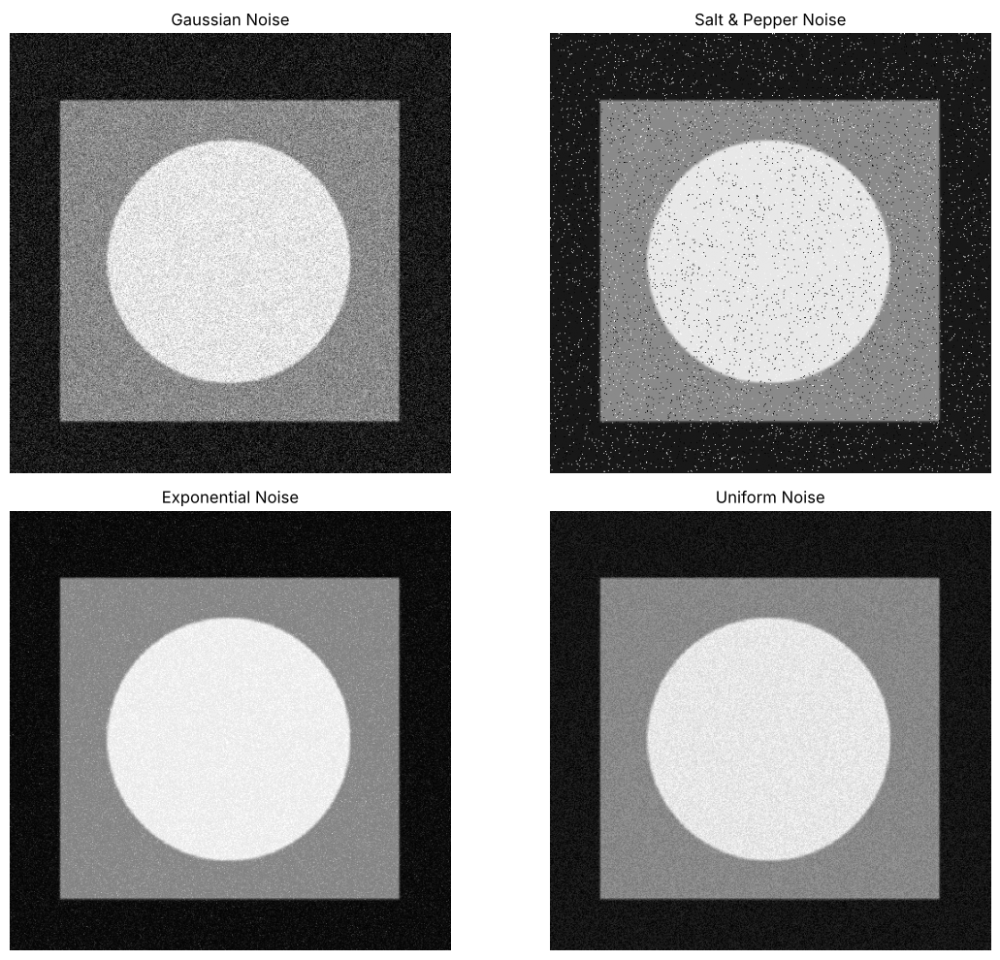

PSNR of noisy image (Gaussian     ): 20.85 dB
PSNR of noisy image (Salt & Pepper): 18.52 dB
PSNR of noisy image (Exponential  ): 25.69 dB
PSNR of noisy image (Uniform      ): 26.87 dB
PSNR of noisy image (Salt only    ): 17.73 dB
PSNR of noisy image (Pepper only  ): 19.33 dB


In [2]:
# ========== ( Adding noise to an Image ) =================

# 0. Read an Image
imgPath = 'Images/noise.jpg'
img = cv2.imread(imgPath, 0)
print('Image shape:', img.shape)

# 1. Function that handle all noise algorithm (Gaussian, Exp, Uniform & Salt&Pepper)
def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black pixels)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)

    # Added: salt only / pepper only (needed for contra-harmonic, max and min filters)
    elif noise_type in ("salt", "pepper"):
        amount = 0.04
        noisy = np.copy(image)
        num = int(np.ceil(amount * image.size))
        coords = [np.random.randint(0, i, num) for i in image.shape]
        noisy[tuple(coords)] = 255 if noise_type == "salt" else 0
        return noisy


# 2. Generate Noisy Images
noise_gauss  = add_noise(img, "gaussian")
noise_sp     = add_noise(img, "salt_pepper")
noise_expo   = add_noise(img, "exponential")
noise_uni    = add_noise(img, "uniform")
noise_salt   = add_noise(img, "salt")
noise_pepper = add_noise(img, "pepper")

# 3. Display in 2x2 Grid
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp, cmap='gray'), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo, cmap='gray'), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni, cmap='gray'), plt.title('Uniform Noise')
for i in range(1, 5):
    plt.subplot(220 + i).axis('off')
plt.tight_layout()
plt.show()

noisy_images = {'Gaussian': noise_gauss, 'Salt & Pepper': noise_sp,
                'Exponential': noise_expo, 'Uniform': noise_uni,
                'Salt only': noise_salt, 'Pepper only': noise_pepper}
for name, im in noisy_images.items():
    print(f'PSNR of noisy image ({name:13s}): {psnr(img, im):.2f} dB')

## **Arithmetic Mean Filter**
Each pixel is replaced by the average of its m×n neighbourhood: **f̂(x, y) = (1/mn) · Σ g(s, t)**

Max difference between the two methods: 0
PSNR noisy: 20.85 dB | after 3x3 mean: 30.01 dB


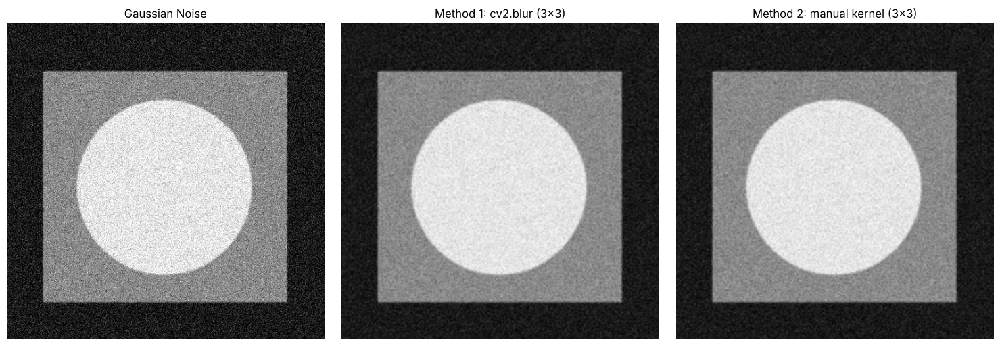

In [3]:
# --- METHOD 1: Using Built-in OpenCV function ---
# The larger the kernel, the smoother the image becomes.
filtered_img = cv2.blur(noise_gauss, (3, 3))

# --- METHOD 2: Manual implementation using a Kernel ---
# An Arithmetic Mean kernel is a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

print('Max difference between the two methods:',
      np.abs(filtered_img.astype(int) - arithmetic_mean_manual.astype(int)).max())
print(f'PSNR noisy: {psnr(img, noise_gauss):.2f} dB | after 3x3 mean: {psnr(img, filtered_img):.2f} dB')

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(132), plt.imshow(filtered_img, cmap='gray'), plt.title('Method 1: cv2.blur (3×3)')
plt.subplot(133), plt.imshow(arithmetic_mean_manual, cmap='gray'), plt.title('Method 2: manual kernel (3×3)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** both methods give the same result (difference ≤ 1 grey level from rounding). The mean filter reduces Gaussian noise and increases the PSNR, but it also slightly blurs the edges of the square and circle.

## **Geometric Means**
**f̂(x, y) = [ Π g(s, t) ]^(1/mn)** – computed as exp(mean(log g)). It smooths like the arithmetic mean but keeps a bit more detail.

PSNR noisy: 20.85 dB | after geometric mean: 24.18 dB


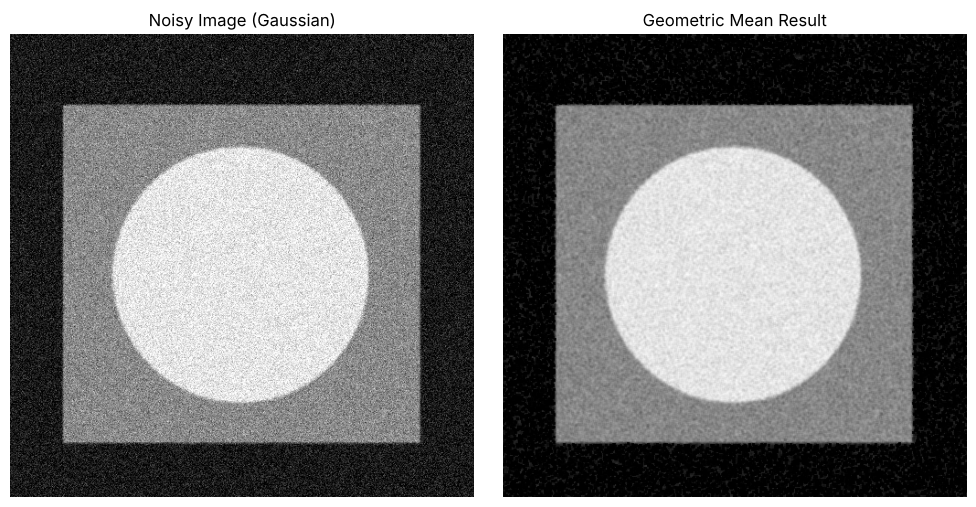

In [4]:
def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6
    # 2. Apply the log-transform
    log_img = np.log(img_float)
    # 3. Apply a box filter to the log image (average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)
    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)
    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


noise_img = noise_gauss
result = geometric_mean_filter(noise_img, kernel_size=3)
print(f'PSNR noisy: {psnr(img, noise_img):.2f} dB | after geometric mean: {psnr(img, result):.2f} dB')

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image (Gaussian)')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('Geometric Mean Result')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** the geometric mean reduces the Gaussian noise (PSNR 20.85 dB to 24.18 dB), but less than the arithmetic mean (30.01 dB). In the dark background some noisy pixels are clipped to 0, and a single value near 0 pulls the whole product down, so this filter is sensitive to dark (pepper-like) values.

## **Harmonic Means Filter**
**f̂(x, y) = mn / Σ (1 / g(s, t))** – works well for **salt** noise and Gaussian-like noise, but **fails for pepper** noise (a 0 pixel makes 1/g huge, so the result becomes 0).

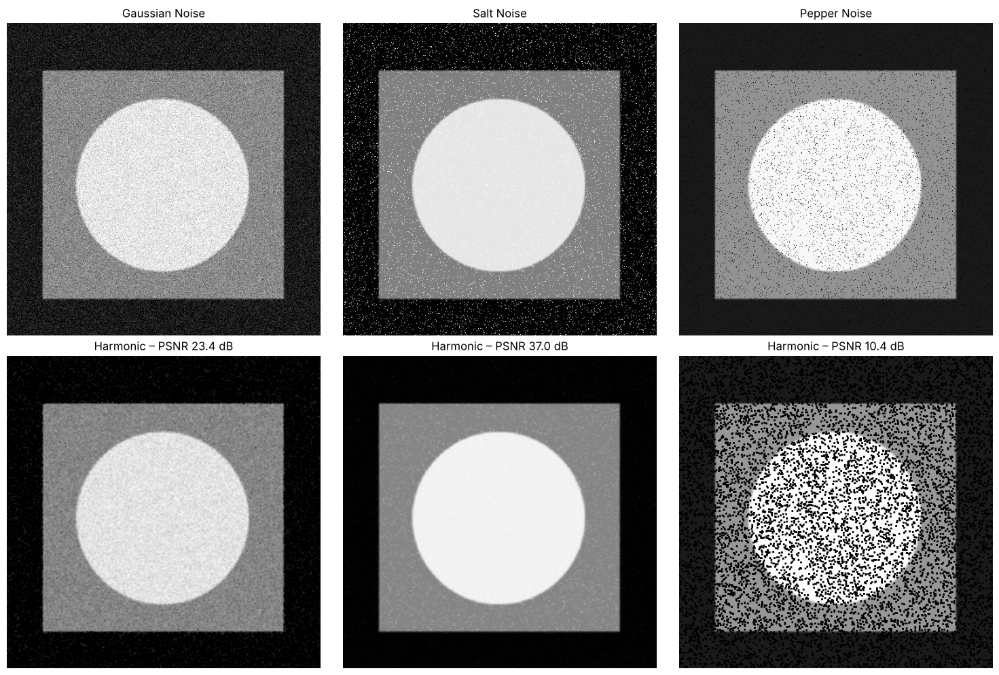

In [5]:
def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6
    # 2. Reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float
    # 3. Sum the reciprocals in a window
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)
    # 4. (Window Size) / Sum of Reciprocals
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal
    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


harm_gauss  = harmonic_mean_filter(noise_gauss, 3)
harm_salt   = harmonic_mean_filter(noise_salt, 3)
harm_pepper = harmonic_mean_filter(noise_pepper, 3)

plt.figure(figsize=(15, 10))
plt.subplot(231), plt.imshow(noise_gauss, cmap='gray'),  plt.title('Gaussian Noise')
plt.subplot(232), plt.imshow(noise_salt, cmap='gray'),   plt.title('Salt Noise')
plt.subplot(233), plt.imshow(noise_pepper, cmap='gray'), plt.title('Pepper Noise')
plt.subplot(234), plt.imshow(harm_gauss, cmap='gray'),   plt.title(f'Harmonic – PSNR {psnr(img, harm_gauss):.1f} dB')
plt.subplot(235), plt.imshow(harm_salt, cmap='gray'),    plt.title(f'Harmonic – PSNR {psnr(img, harm_salt):.1f} dB')
plt.subplot(236), plt.imshow(harm_pepper, cmap='gray'),  plt.title(f'Harmonic – PSNR {psnr(img, harm_pepper):.1f} dB')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** the harmonic mean removes the salt (white) dots almost completely, but on pepper noise every black dot grows into a black 3×3 block, so the image gets worse. This matches the theory.

## **Contra - Harmonic Mean Filter**
**f̂(x, y) = Σ g(s, t)^(Q+1) / Σ g(s, t)^Q**
- **Q > 0** removes **pepper** noise
- **Q < 0** removes **salt** noise
- Q = 0 gives the arithmetic mean, Q = −1 gives the harmonic mean

Choosing the wrong sign of Q makes the noise worse, so each case is shown with the correct and the wrong Q.

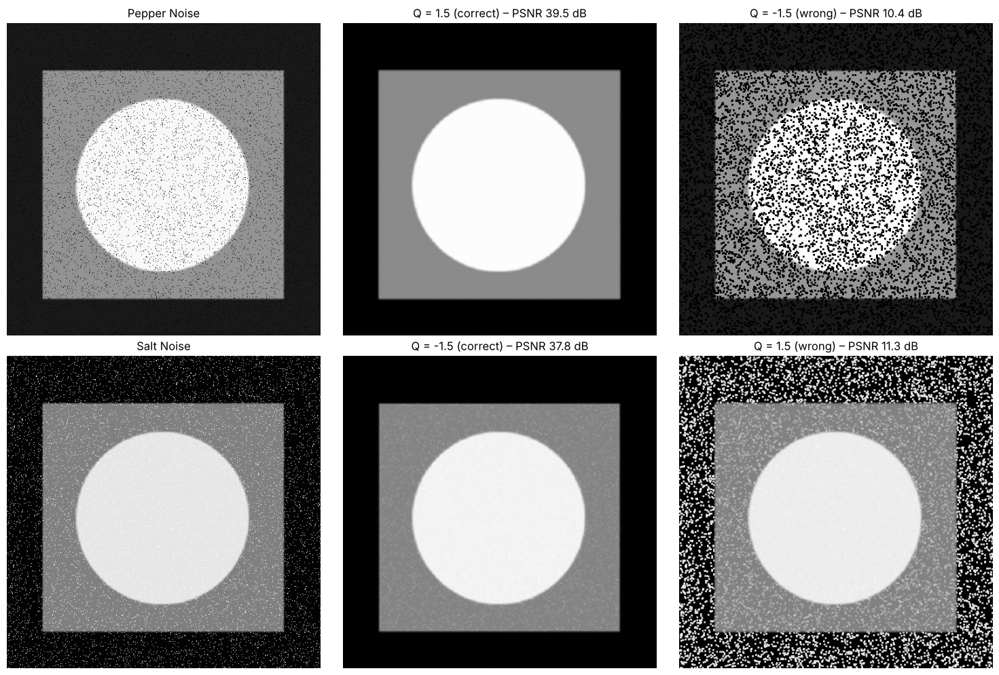

In [6]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6
    # 2. Numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)
    # 3. Denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)
    # 4. Divide (avoid division by zero)
    result = num_sum / (den_sum + 1e-6)
    return np.clip(result, 0, 255).astype(np.uint8)


# Q > 0 (1.5): removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_pepper, kernel_size=3, Q=1.5)
pepper_wrongQ  = contra_harmonic_mean(noise_pepper, kernel_size=3, Q=-1.5)

# Q < 0 (-1.5): removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_salt, kernel_size=3, Q=-1.5)
salt_wrongQ  = contra_harmonic_mean(noise_salt, kernel_size=3, Q=1.5)

plt.figure(figsize=(15, 10))
plt.subplot(231), plt.imshow(noise_pepper, cmap='gray'),   plt.title('Pepper Noise')
plt.subplot(232), plt.imshow(pepper_removed, cmap='gray'), plt.title(f'Q = 1.5 (correct) – PSNR {psnr(img, pepper_removed):.1f} dB')
plt.subplot(233), plt.imshow(pepper_wrongQ, cmap='gray'),  plt.title(f'Q = -1.5 (wrong) – PSNR {psnr(img, pepper_wrongQ):.1f} dB')
plt.subplot(234), plt.imshow(noise_salt, cmap='gray'),     plt.title('Salt Noise')
plt.subplot(235), plt.imshow(salt_removed, cmap='gray'),   plt.title(f'Q = -1.5 (correct) – PSNR {psnr(img, salt_removed):.1f} dB')
plt.subplot(236), plt.imshow(salt_wrongQ, cmap='gray'),    plt.title(f'Q = 1.5 (wrong) – PSNR {psnr(img, salt_wrongQ):.1f} dB')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** with the correct sign of Q the dots disappear and the PSNR is high. With the wrong sign the dots are spread into larger blobs and the PSNR drops.

## **Median Filter**
Replaces each pixel with the **median** of its neighbourhood. Salt (255) and pepper (0) values are extremes, so they are never the median – this makes the median filter the best choice for salt & pepper noise, and it keeps edges sharp.

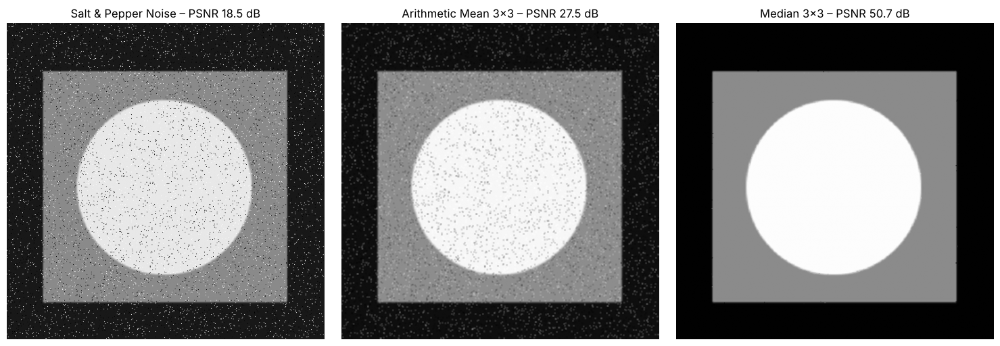

In [7]:
noise_img = noise_sp

# Apply Median Filter – ksize MUST be an odd integer (3, 5, 7, ...)
median_result = cv2.medianBlur(noise_img, 3)
mean_result   = cv2.blur(noise_img, (3, 3))      # for comparison

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img, cmap='gray'),     plt.title(f'Salt & Pepper Noise – PSNR {psnr(img, noise_img):.1f} dB')
plt.subplot(132), plt.imshow(mean_result, cmap='gray'),   plt.title(f'Arithmetic Mean 3×3 – PSNR {psnr(img, mean_result):.1f} dB')
plt.subplot(133), plt.imshow(median_result, cmap='gray'), plt.title(f'Median 3×3 – PSNR {psnr(img, median_result):.1f} dB')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** the median filter removes almost all salt & pepper dots and keeps the edges sharp. The mean filter only spreads each dot into a grey patch, so its PSNR is much lower.

## **Max and Min Filter**
- **Max filter** (dilation) picks the brightest pixel in the window, so it removes **pepper** (black) noise.
- **Min filter** (erosion) picks the darkest pixel in the window, so it removes **salt** (white) noise.

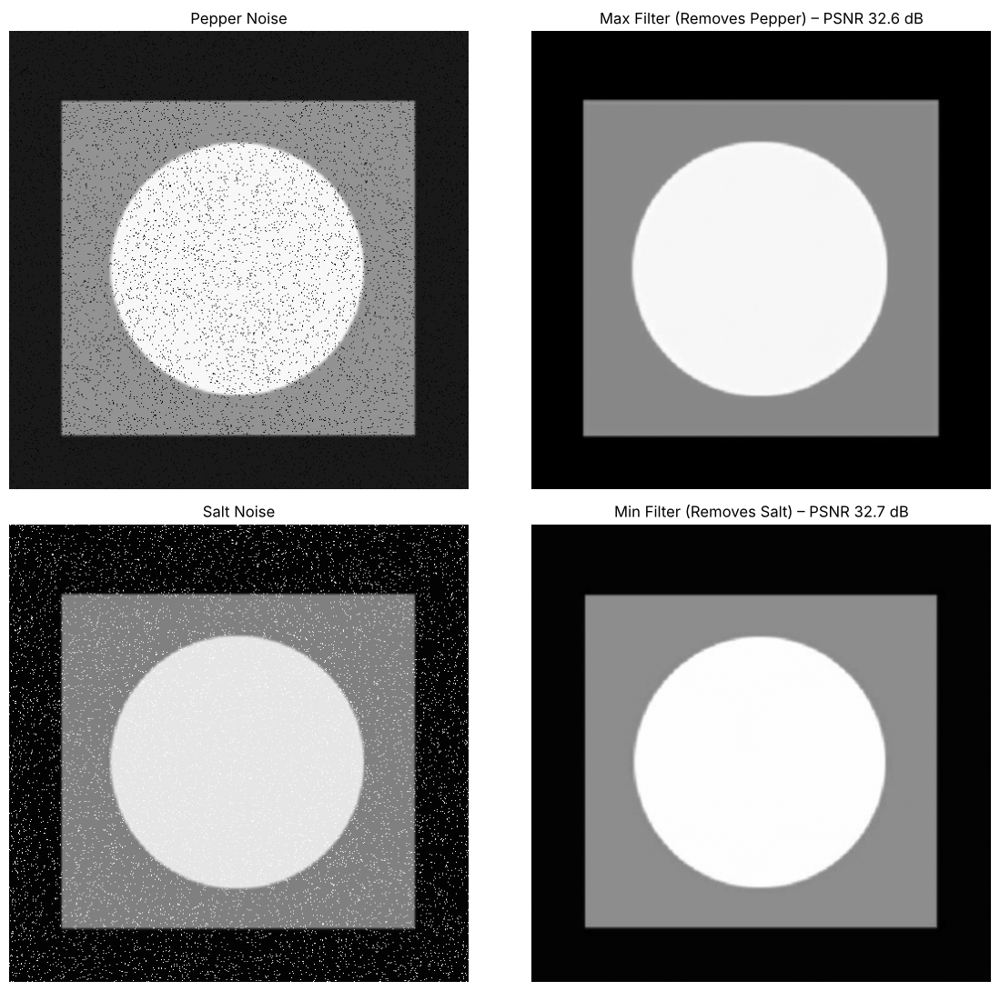

In [8]:
# Define the Kernel size (3x3)
kernel = np.ones((3, 3), np.uint8)

# Max Filter (Dilation) on pepper noise
max_filter = cv2.dilate(noise_pepper, kernel)

# Min Filter (Erosion) on salt noise
min_filter = cv2.erode(noise_salt, kernel)

plt.figure(figsize=(12, 11))
plt.subplot(221), plt.imshow(noise_pepper, cmap='gray'), plt.title('Pepper Noise')
plt.subplot(222), plt.imshow(max_filter, cmap='gray'),   plt.title(f'Max Filter (Removes Pepper) – PSNR {psnr(img, max_filter):.1f} dB')
plt.subplot(223), plt.imshow(noise_salt, cmap='gray'),   plt.title('Salt Noise')
plt.subplot(224), plt.imshow(min_filter, cmap='gray'),   plt.title(f'Min Filter (Removes Salt) – PSNR {psnr(img, min_filter):.1f} dB')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** the max filter removes the black dots and the min filter removes the white dots. As a side effect, the max filter makes bright regions slightly larger and the min filter makes them slightly smaller.

## **Mid-Point Filtering**
**f̂(x, y) = ½ [ max g(s, t) + min g(s, t) ]** – works best for randomly distributed noise such as **Gaussian or uniform** noise.

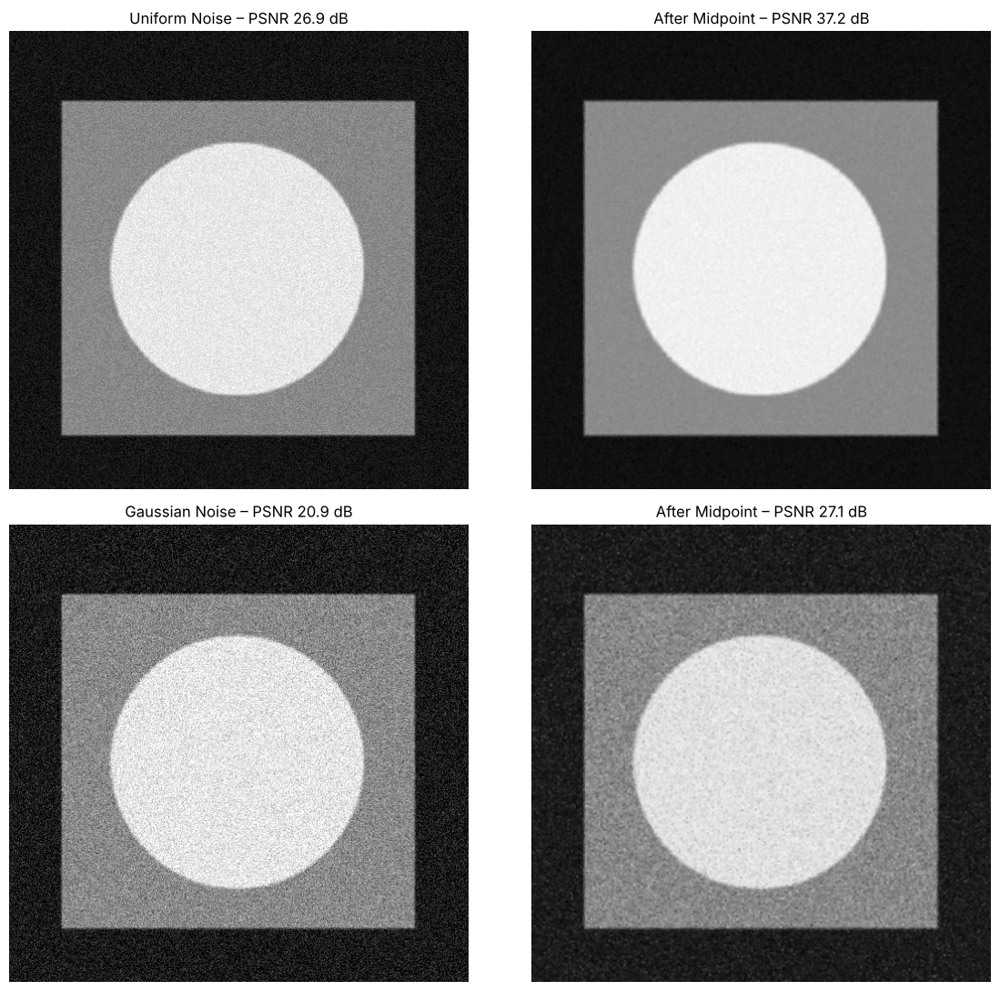

In [9]:
def midpoint_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    max_img = cv2.dilate(image, kernel).astype(np.float64)   # neighbourhood max
    min_img = cv2.erode(image, kernel).astype(np.float64)    # neighbourhood min
    midpoint = (max_img + min_img) / 2
    return midpoint.astype(np.uint8)


mid_uni   = midpoint_filter(noise_uni, kernel_size=3)
mid_gauss = midpoint_filter(noise_gauss, kernel_size=3)

plt.figure(figsize=(12, 11))
plt.subplot(221), plt.imshow(noise_uni, cmap='gray'),   plt.title(f'Uniform Noise – PSNR {psnr(img, noise_uni):.1f} dB')
plt.subplot(222), plt.imshow(mid_uni, cmap='gray'),     plt.title(f'After Midpoint – PSNR {psnr(img, mid_uni):.1f} dB')
plt.subplot(223), plt.imshow(noise_gauss, cmap='gray'), plt.title(f'Gaussian Noise – PSNR {psnr(img, noise_gauss):.1f} dB')
plt.subplot(224), plt.imshow(mid_gauss, cmap='gray'),   plt.title(f'After Midpoint – PSNR {psnr(img, mid_gauss):.1f} dB')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** the midpoint filter improves the uniform-noise image the most, because uniform noise is bounded (±20), so the average of the max and min in the window is close to the true value.

## Comparison of all filters (PSNR in dB, 3×3 window)
Every filter is applied to every noise type. The best filter for each noise type is highlighted.

In [10]:
filters = {
    'Arithmetic Mean':        lambda im: cv2.blur(im, (3, 3)),
    'Geometric Mean':         lambda im: geometric_mean_filter(im, 3),
    'Harmonic Mean':          lambda im: harmonic_mean_filter(im, 3),
    'Contra-Harmonic Q=1.5':  lambda im: contra_harmonic_mean(im, 3, Q=1.5),
    'Contra-Harmonic Q=-1.5': lambda im: contra_harmonic_mean(im, 3, Q=-1.5),
    'Median':                 lambda im: cv2.medianBlur(im, 3),
    'Max':                    lambda im: cv2.dilate(im, np.ones((3, 3), np.uint8)),
    'Min':                    lambda im: cv2.erode(im, np.ones((3, 3), np.uint8)),
    'Midpoint':               lambda im: midpoint_filter(im, 3),
}

rows = {'(no filter)': {n: psnr(img, im) for n, im in noisy_images.items()}}
for fname, f in filters.items():
    rows[fname] = {n: psnr(img, f(im)) for n, im in noisy_images.items()}

table = pd.DataFrame(rows).T.round(2)
display(table.style.highlight_max(axis=0, color='#b6e3b6').format('{:.2f}'))

print('Best filter for each noise type:')
for noise in table.columns:
    print(f'  {noise:13s}: {table[noise].drop("(no filter)").idxmax()}')

,Gaussian,Salt & Pepper,Exponential,Uniform,Salt only,Pepper only
(no filter),20.85,18.52,25.69,26.87,17.73,19.33
Arithmetic Mean,30.01,27.52,28.21,35.81,25.97,27.59
Geometric Mean,24.18,14.19,29.31,33.80,33.66,11.37
Harmonic Mean,23.44,13.19,29.85,31.25,37.02,10.44
Contra-Harmonic Q=1.5,23.28,14.04,26.17,32.35,11.25,39.51
Contra-Harmonic Q=-1.5,23.01,13.19,30.32,29.32,37.79,10.44
Median,27.73,50.67,30.19,32.34,46.63,48.18
Max,16.64,11.56,18.77,23.36,8.84,32.64
Min,17.18,13.16,33.44,22.91,32.67,10.43
Midpoint,27.12,15.65,24.99,37.17,14.95,16.50


Best filter for each noise type:
  Gaussian     : Arithmetic Mean
  Salt & Pepper: Median
  Exponential  : Min
  Uniform      : Midpoint
  Salt only    : Median
  Pepper only  : Median


**Observation:**
- **Gaussian:** the arithmetic mean is best (30.01 dB), followed by the median and the midpoint.
- **Uniform:** the midpoint filter is best (37.17 dB), because uniform noise is bounded.
- **Exponential:** the min filter is best (33.44 dB). Exponential noise only adds positive values (it makes pixels brighter), so taking the minimum of the window removes this bias. Contra-harmonic with Q < 0 and the harmonic mean are next for the same reason.
- **Salt & Pepper:** the median is by far the best (50.67 dB vs 27.52 dB for the mean).
- **Salt only / Pepper only:** the median is best here too (46.63 / 48.18 dB), because only 4% of the pixels are noisy. The specialised filters come next: contra-harmonic Q < 0 (37.79 dB) and the harmonic mean for salt, contra-harmonic Q > 0 (39.51 dB) and the max filter for pepper.
- Using the wrong filter makes the image **worse than the noisy input**, for example the harmonic mean on pepper noise (10.44 dB vs 19.33 dB) or the max filter on salt noise (8.84 dB).

## Applying the filters to real noisy images
### `person.jpg` – real salt & pepper noise

Person shape: (224, 225)


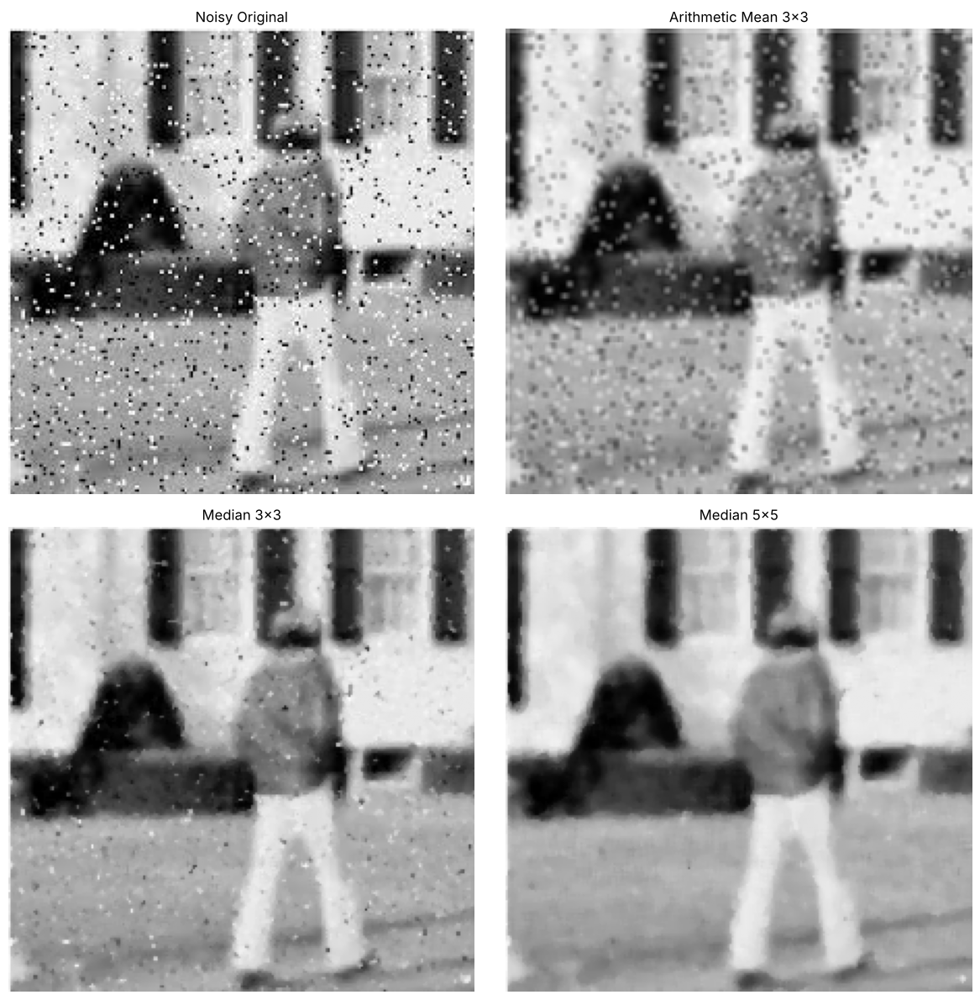

In [11]:
person = cv2.imread('Images/person.jpg', 0)
print('Person shape:', person.shape)

person_mean   = cv2.blur(person, (3, 3))
person_med3   = cv2.medianBlur(person, 3)
person_med5   = cv2.medianBlur(person, 5)

plt.figure(figsize=(12, 12))
plt.subplot(221), plt.imshow(person, cmap='gray'),      plt.title('Noisy Original')
plt.subplot(222), plt.imshow(person_mean, cmap='gray'), plt.title('Arithmetic Mean 3×3')
plt.subplot(223), plt.imshow(person_med3, cmap='gray'), plt.title('Median 3×3')
plt.subplot(224), plt.imshow(person_med5, cmap='gray'), plt.title('Median 5×5')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** the mean filter leaves grey spots where the dots were. The 3×3 median removes most of the dots while keeping the windows and the person sharp. The 5×5 median removes all remaining dots but the image becomes more blurred, so 3×3 is a good balance.

### `dome.jpg` – large noise dots
In this image each noise dot is about 15 pixels wide and smooth (not a single pixel), so the median window must be larger than the dots to remove them.

Dome shape: (673, 672)


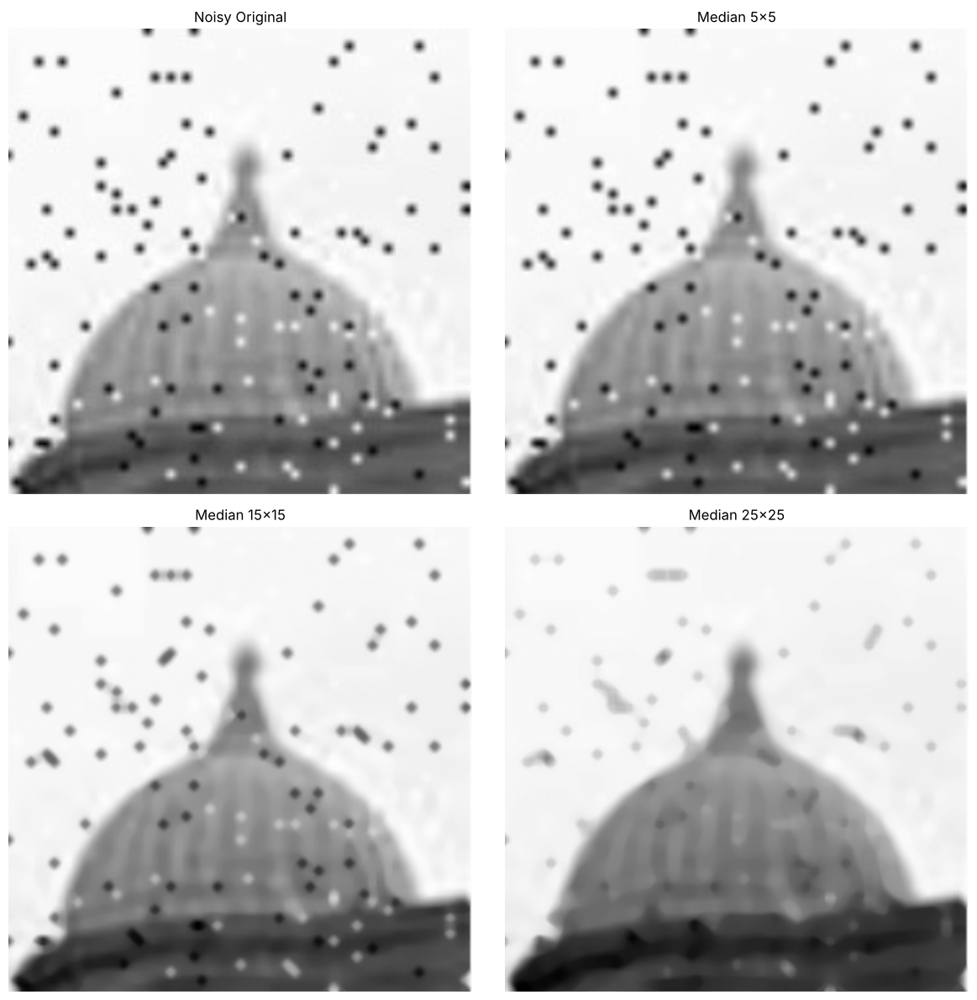

In [12]:
dome = cv2.imread('Images/dome.jpg', 0)
print('Dome shape:', dome.shape)

dome_med5  = cv2.medianBlur(dome, 5)
dome_med15 = cv2.medianBlur(dome, 15)
dome_med25 = cv2.medianBlur(dome, 25)

plt.figure(figsize=(12, 12))
plt.subplot(221), plt.imshow(dome, cmap='gray'),       plt.title('Noisy Original')
plt.subplot(222), plt.imshow(dome_med5, cmap='gray'),  plt.title('Median 5×5')
plt.subplot(223), plt.imshow(dome_med15, cmap='gray'), plt.title('Median 15×15')
plt.subplot(224), plt.imshow(dome_med25, cmap='gray'), plt.title('Median 25×25')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** small windows (5×5) do not change the large dots at all. A 15×15 window only makes them lighter, and 25×25 removes almost all of them (only faint traces remain), but the dome also becomes more blurred. The window size must be chosen according to the size of the noise.

## Conclusion

| Noise type | Best filter(s) |
|---|---|
| Gaussian | Arithmetic mean |
| Uniform | Midpoint, arithmetic mean |
| Exponential | Min filter, contra-harmonic with Q < 0 |
| Salt & Pepper | Median |
| Pepper only (black dots) | Median, contra-harmonic with Q > 0, max filter |
| Salt only (white dots) | Median, contra-harmonic with Q < 0, harmonic mean |

- Mean filters reduce random noise but blur edges.
- Order-statistic filters (median, max, min, midpoint) are better for impulse noise; the median removes salt & pepper while keeping edges sharp.
- Choosing the wrong filter (for example, the harmonic mean on pepper noise or the wrong sign of Q) makes the image worse.
- The kernel size must match the size of the noise: larger windows remove larger noise but blur the image more.